# Multimodal Capabilities (Notebook-Friendly)

This notebook demonstrates the same capabilities as the Python scripts in `langChain/multimodal/`:
- Image → Text (`image_to_text.py`)
- Text → Image (`text_to_image.py`)
- Text → Speech (`text_to_speech.py`)
- Speech → Text (`speech_to_text.py`)

Design goals:
- No environment-variable reads in notebook code
- Clear step labels
- Consistent snake_case variable naming


## Step 0: Setup
Run this first.


In [2]:
import base64
import time
from pathlib import Path

import requests
from dotenv import load_dotenv
from envyaml import EnvYAML
from IPython.display import Image, display
import IPython.display as ipd

from langChain.oci_openai_helper import OCIOpenAIHelper

load_dotenv()
config = EnvYAML('sandbox.yaml')
sync_openai_client = OCIOpenAIHelper.get_sync_openai_client(config=config)

base_dir = Path('langChain/multimodal')
scratch_dir = Path('scratch')
scratch_dir.mkdir(parents=True, exist_ok=True)

print('Ready. Profile:', config['oci']['profile'])


Ready. Profile: INNOLAB-LEARNING


---
## Capability 1: Image → Text
### Step 1.1: Set inputs


Image: langChain/multimodal/otter.png


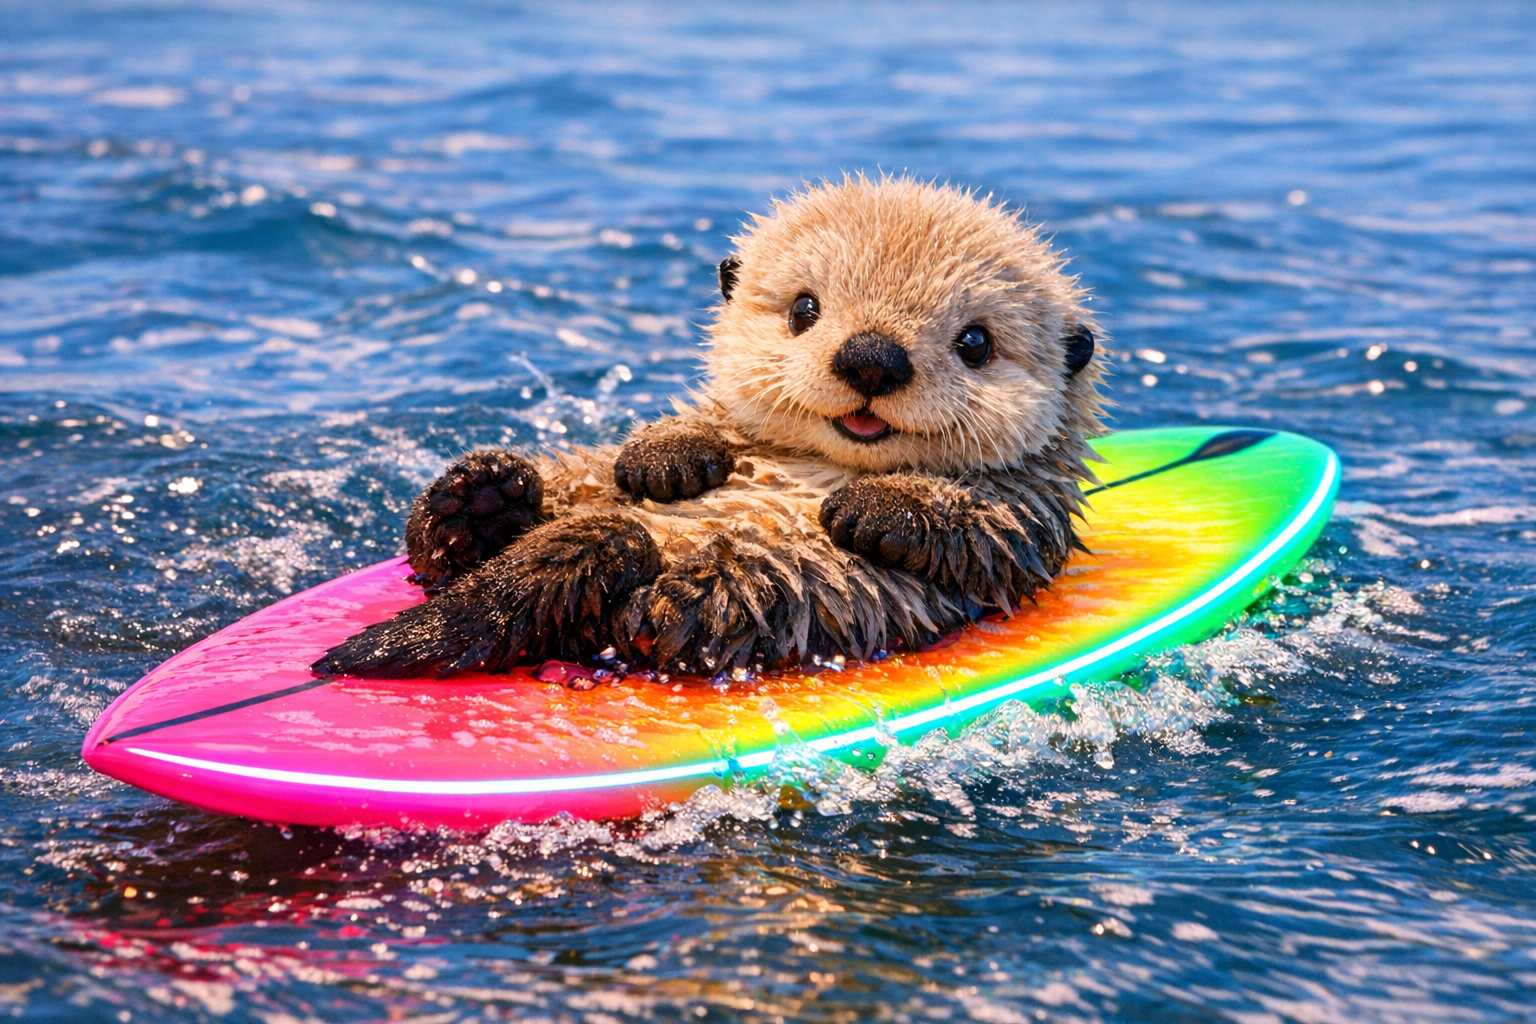

In [3]:
model_list = [
    'meta.llama-4-scout-17b-16e-instruct',
    'openai.gpt-4.1',
    'xai.grok-4',
]

default_image_path = base_dir / 'otter.png'
fallback_image_path = Path('oci_genai/vision/dussera-b.jpg')
image_path = str(default_image_path if default_image_path.exists() else fallback_image_path)
user_text = 'Describe this image with key objects and context.'

print('Image:', image_path)
display(Image(filename=image_path))


### Step 1.2: Build multimodal payload


In [4]:
image_b64 = base64.b64encode(Path(image_path).read_bytes()).decode('utf-8')
messages = [{
    'role': 'user',
    'content': [
        {'type': 'text', 'text': user_text},
        {'type': 'image_url', 'image_url': {'url': f'data:image/jpeg;base64,{image_b64}'}}
    ]
}]
print('Payload ready')


Payload ready


### Step 1.3: Invoke models


In [5]:
for model_name in model_list:
    print('\n' + '=' * 70)
    print('Model:', model_name)
    model_client = OCIOpenAIHelper.get_langchain_openai_client(model_name=model_name, config=config)
    start_time = time.time()
    model_response = model_client.invoke(messages)
    print(model_response.content)
    print(f'Latency: {time.time() - start_time:.2f}s')



Model: meta.llama-4-scout-17b-16e-instruct
The image depicts a sea otter riding a surfboard on the water. 

**Key objects in the image:**

* A sea otter
* A surfboard

**Context of the image:**

The sea otter is lying on its back on a rainbow-colored surfboard, with its paws raised and its head turned to face the camera. The surfboard is floating on the surface of the water, which appears to be choppy and blue. The overall atmosphere suggests a fun and playful scene, with the sea otter appearing to enjoy its ride on the surfboard.
Latency: 3.26s

Model: openai.gpt-4.1
This image features a cute baby otter lying on its back atop a brightly colored surfboard in the water. The surfboard has a gradient rainbow color scheme, including pink, orange, yellow, green, and blue. The otter looks happy and playful, with its tongue sticking out and its front paws resting on its belly. The setting is an open body of water, likely the sea or an ocean, with gentle waves splashing around the surfboard,

---
## Capability 2: Text → Image
### Step 2.1: Set hard-coded defaults


In [6]:
image_model = 'openai.gpt-image-1.5'
image_size = '1536x1024'
image_prompt = 'A cute baby sea otter floating on a neon surfboard'
image_output_path = base_dir / 'otter.png'

print('Model:', image_model)
print('Size :', image_size)
print('Out  :', image_output_path)


Model: openai.gpt-image-1.5
Size : 1536x1024
Out  : langChain/multimodal/otter.png


### Step 2.2: Generate image


Saved: /Users/ashish/work/code/python/workshop/langChain/multimodal/otter.png


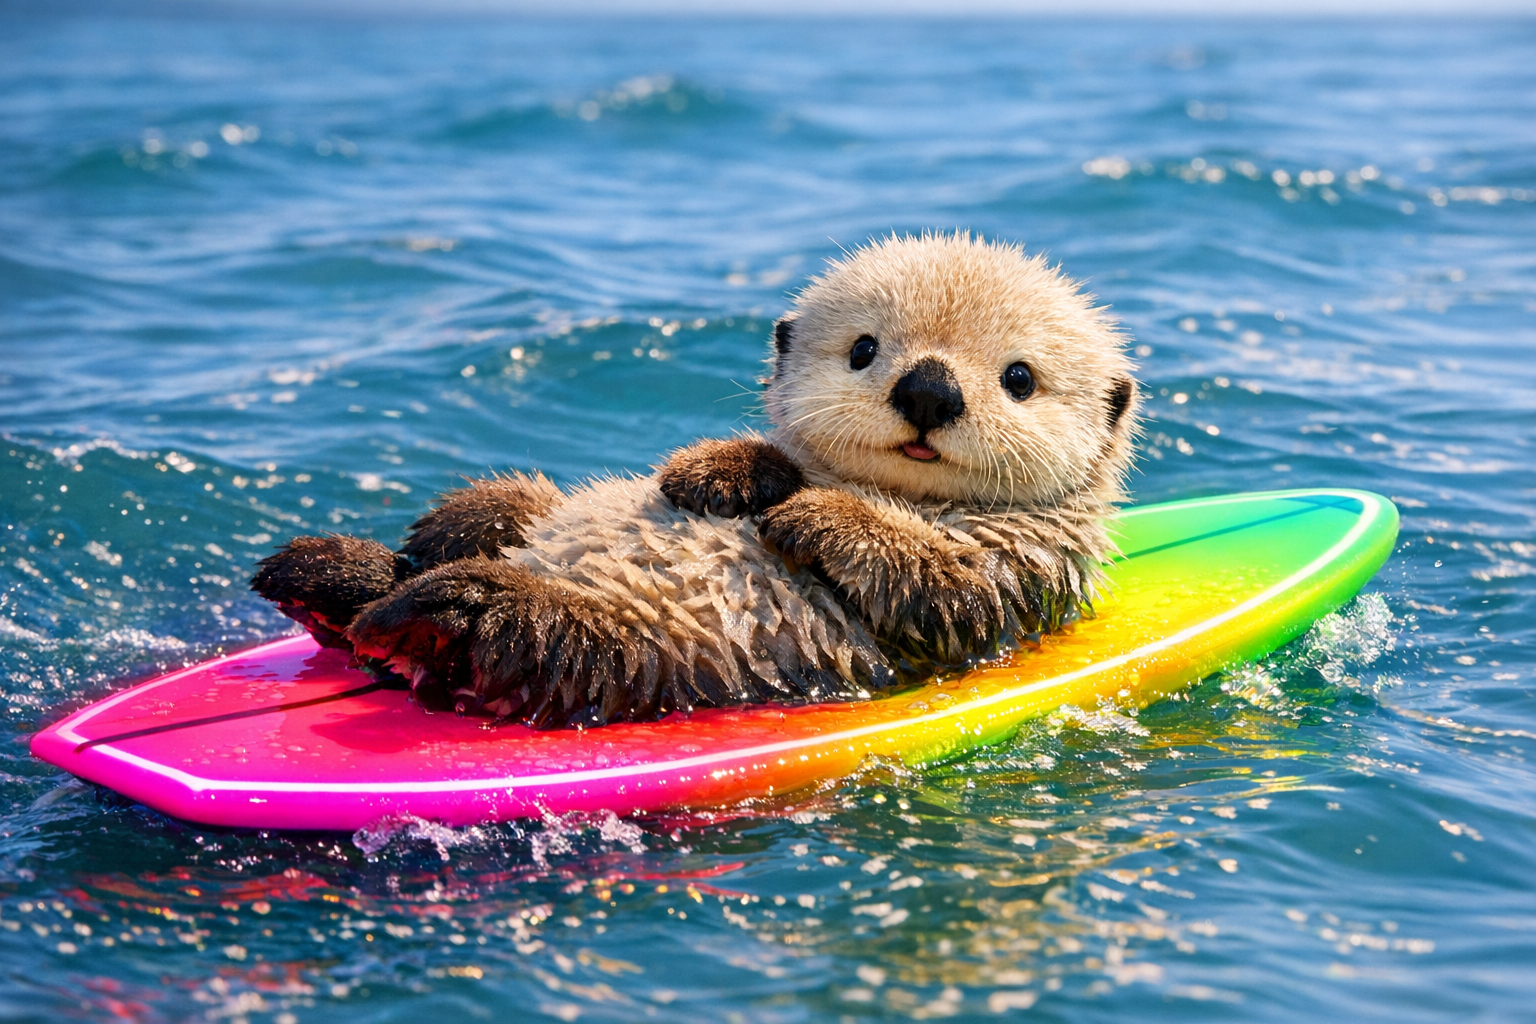

In [7]:
image_response = sync_openai_client.images.generate(
    model=image_model,
    prompt=image_prompt,
    n=1,
    size=image_size,
)
image_bytes = base64.b64decode(image_response.data[0].b64_json)
image_output_path.parent.mkdir(parents=True, exist_ok=True)
image_output_path.write_bytes(image_bytes)
print('Saved:', image_output_path.resolve())
display(Image(filename=str(image_output_path)))


---
## Capability 3: Text → Speech
### Step 3.1: Set hard-coded defaults


In [8]:
audio_model = 'openai.gpt-audio'
voice_name = 'alloy'
audio_format = 'wav'
audio_prompt = 'Is a golden retriever a good family dog?'
audio_output_path = Path('scratch/dog.wav')

print('Model:', audio_model)
print('Voice:', voice_name)
print('Out  :', audio_output_path)


Model: openai.gpt-audio
Voice: alloy
Out  : scratch/dog.wav


### Step 3.2: Generate speech


In [9]:
tts_response = sync_openai_client.chat.completions.create(
    model=audio_model,
    modalities=['text', 'audio'],
    audio={'voice': voice_name, 'format': audio_format},
    messages=[{'role': 'user', 'content': audio_prompt}],
)
audio_bytes = base64.b64decode(tts_response.choices[0].message.audio.data)
audio_output_path.parent.mkdir(parents=True, exist_ok=True)
audio_output_path.write_bytes(audio_bytes)
print('Saved:', audio_output_path.resolve())
display(ipd.Audio(filename=str(audio_output_path)))


Saved: /Users/ashish/work/code/python/workshop/scratch/dog.wav


---
## Capability 4: Speech → Text
### Step 4.1: Set hard-coded defaults


In [10]:
transcribe_model = 'openai.gpt-audio'
transcribe_url = 'https://cdn.openai.com/API/docs/audio/alloy.wav'
transcribe_cache_path = Path('scratch/reference_audio.wav')
transcribe_prompt = 'What is in this recording?'

transcribe_cache_path.parent.mkdir(parents=True, exist_ok=True)
if transcribe_cache_path.exists():
    wav_bytes = transcribe_cache_path.read_bytes()
else:
    download_response = requests.get(transcribe_url, timeout=30)
    download_response.raise_for_status()
    wav_bytes = download_response.content
    transcribe_cache_path.write_bytes(wav_bytes)

print('Audio ready:', transcribe_cache_path.resolve())
display(ipd.Audio(filename=str(transcribe_cache_path)))


Audio ready: /Users/ashish/work/code/python/workshop/scratch/reference_audio.wav


### Step 4.2: Transcribe audio


In [11]:
wav_b64 = base64.b64encode(wav_bytes).decode('utf-8')
stt_response = sync_openai_client.chat.completions.create(
    model=transcribe_model,
    modalities=['text', 'audio'],
    audio={'voice': 'alloy', 'format': 'wav'},
    messages=[{
        'role': 'user',
        'content': [
            {'type': 'text', 'text': transcribe_prompt},
            {'type': 'input_audio', 'input_audio': {'data': wav_b64, 'format': 'wav'}}
        ]
    }],
)

transcript_text = stt_response.choices[0].message.audio.transcript
transcript_path = transcribe_cache_path.with_suffix('.transcript.txt')
transcript_path.write_text(transcript_text)
print('Transcript:')
print(transcript_text)
print('Saved:', transcript_path.resolve())


Transcript:
This recording describes the fact that the sun rises in the east and sets in the west, something humans have observed for thousands of years. It’s a basic observation about the movement of the sun in the sky.
Saved: /Users/ashish/work/code/python/workshop/scratch/reference_audio.transcript.txt


## Done
This version uses hard-coded defaults and consistent variable naming throughout.
